<a href="https://colab.research.google.com/github/hafizzx/Machine-Learning-Algorithms/blob/main/Ridge_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, ridge_regression , Ridge
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score


In [3]:
df = pd.read_csv("/content/cgpa_package_100_rows.csv")
df.head(5)

,CGPA,Package_PKR
0,3.32,358794
1,2.32,236163
2,3.58,362746
3,3.09,360581
4,1.28,156293


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   CGPA         100 non-null    float64
 1   Package_PKR  100 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 1.7 KB


In [5]:
X = df.iloc[:,0]
y = df.iloc[:,1]

In [8]:
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size= 0.2)

In [9]:
lr = LinearRegression()

In [10]:
lr.fit(X_train.values.reshape(-1,1),y_train)

LinearRegression()

In [11]:
lr.coef_

array([91040.66270282])

In [12]:
lr.intercept_

np.float64(49481.50762483277)

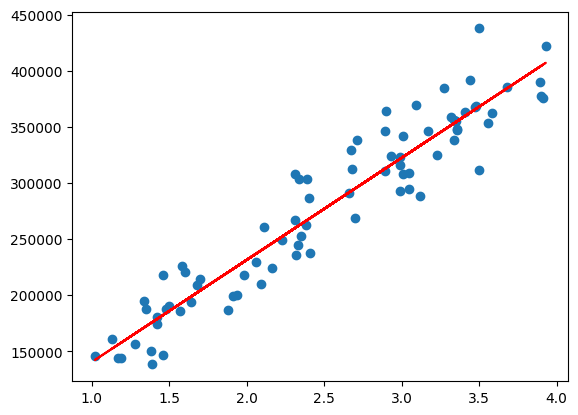

In [13]:
plt.scatter(X_train,y_train)
plt.plot(X_train,lr.predict(X_train.values.reshape(-1,1)),color='red')
plt.show()

In [14]:
rr = Ridge(alpha = 10)
rr.fit(X_train.values.reshape(-1,1),y_train)
print(rr.coef_)
print(rr.intercept_)

[76819.24672423]
85209.25991705747


In [15]:
rr1 = Ridge(alpha = 100)
rr1.fit(X_train.values.reshape(-1,1),y_train)
print(rr1.coef_)
print(rr1.intercept_)

[31929.71903937]
197982.97584334982


In [16]:
rr2 = Ridge(alpha = 200)
rr2.fit(X_train.values.reshape(-1,1),y_train)
print(rr2.coef_)
print(rr2.intercept_)

[19359.78476426]
229561.7932259898


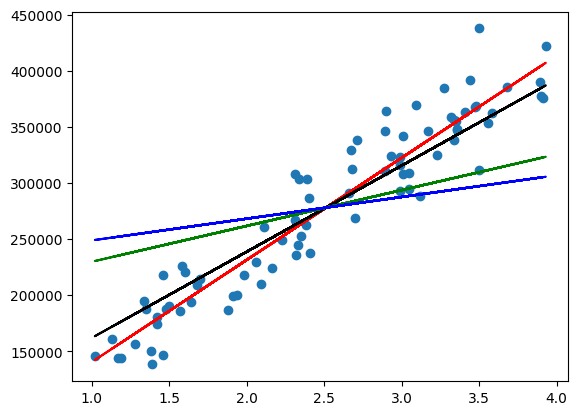

In [19]:
plt.scatter(X_train,y_train)
plt.plot(X_train,lr.predict(X_train.values.reshape(-1,1)),color='red')
plt.plot(X_train,rr.predict(X_train.values.reshape(-1,1)),color='Black')
plt.plot(X_train,rr1.predict(X_train.values.reshape(-1,1)),color='green')
plt.plot(X_train,rr2.predict(X_train.values.reshape(-1,1)),color='blue')

In [20]:
r2_score(y_test,lr.predict(X_test.values.reshape(-1,1)))

0.8625164117997108

In [21]:
r2_score(y_test,rr1.predict(X_test.values.reshape(-1,1)))

0.387878606389257

In [44]:
class MeraRidge:

    def __init__(self, alpha=0.1):
        self.alpha = alpha
        self.m = None
        self.b = None

    def fit(self, X_train, y_train):

        X_train = X_train.to_numpy().reshape(-1) if hasattr(X_train, "to_numpy") else X_train.reshape(-1)
        y_train = y_train.to_numpy().reshape(-1) if hasattr(y_train, "to_numpy") else y_train.reshape(-1)

        x_mean = X_train.mean()
        y_mean = y_train.mean()

        num = 0
        den = 0

        for i in range(len(X_train)):
            num += (X_train[i] - x_mean) * (y_train[i] - y_mean)
            den += (X_train[i] - x_mean) ** 2

        self.m = num / (den + self.alpha)
        self.b = y_mean - self.m * x_mean
        print(self.m)
        print(self.b)

    def predict(self, X_test):

        X_test = X_test.to_numpy().reshape(-1) if hasattr(X_test, "to_numpy") else X_test.reshape(-1)

        return self.m * X_test + self.b

In [47]:
mr = MeraRidge(10)

In [48]:
mr.fit(X_train,y_train)

76819.24672422832
85209.25991705741


In [71]:
df1.isnull().sum()

,0
CGPA,0
IQ_Level,0
Field_Interest,0
Programming_Skill,0
Communication_Skill,0
Salary_Package_PKR,0


In [69]:
df1.dropna(inplace=True)

In [68]:
df1 = pd.read_csv("/content/students_150_multiple_features.csv")
df1.head(5)

,CGPA,IQ_Level,Field_Interest,Programming_Skill,Communication_Skill,Salary_Package_PKR
0,2.75,117.0,1.0,2.0,9.0,319694.0
1,3.90,85.0,5.0,3.0,2.0,344377.0
2,3.46,103.0,6.0,1.0,9.0,335458.0
3,3.20,86.0,3.0,1.0,1.0,266603.0
4,2.31,137.0,9.0,3.0,1.0,317019.0


In [70]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 144 entries, 0 to 149
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CGPA                 144 non-null    float64
 1   IQ_Level             144 non-null    float64
 2   Field_Interest       144 non-null    float64
 3   Programming_Skill    144 non-null    float64
 4   Communication_Skill  144 non-null    float64
 5   Salary_Package_PKR   144 non-null    float64
dtypes: float64(6)
memory usage: 7.9 KB


In [72]:
X = df1.iloc[:,0:5]
y = df1.iloc[:,5]

In [73]:
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size= 0.2)

In [74]:
lr1 = LinearRegression()

In [75]:
lr1.fit(X_train,y_train)

LinearRegression()

In [76]:
lr1.coef_


array([56938.32472631,  1011.67615547,  5880.15114925, 12968.38057379,
        7322.86246506])

In [77]:
lr1.intercept_

np.float64(-45685.117411418)

In [78]:
rr1 = Ridge(alpha = 10)

In [79]:
rr1.fit(X_train,y_train)

Ridge(alpha=10)

In [80]:
rr1.coef_

array([45859.87107456,  1030.92303215,  5959.54582264, 12908.38925616,
        7416.08440684])

In [81]:
rr1.intercept_

np.float64(-15926.60382039647)